# 04 · Infinite languages and certification

A loop gives a model an infinite language. LMP stays well-defined because $\mu$ is a probability measure: $\mu(\mathcal L(M)) \le 1$ for any language. This notebook shows how the library computes it.

**Pipeline.** The Petri net's reachable markings form an ε-NFA (silent transitions are ε-moves, duplicate labels are nondeterminism). Subset construction gives a DFA. The denominator $D=\mu(\mathcal L(M))$ is then obtained by one of three routes:

1. **finite sum** if the productive DFA is acyclic (finite language), for any prior;
2. **sparse linear solve** $x = (1-\lambda)f + \lambda A x$ for the geometric prior, exact even for infinite languages;
3. **certified interval** $D_K \le D \le D_K + s_{K+1}\sum_{n>K}\rho_n$ otherwise, where $s_{K+1}$ is the prior mass still on productive DFA states after $K{+}1$ symbols.

The numerator only needs membership tests for the (finitely many) log variants.

In [1]:
import os, warnings
os.environ["PM4PY_SHOW_PROGRESS_BAR"] = "False"
warnings.filterwarnings("ignore", category=DeprecationWarning)

import language_mass_precision as lmp
import pm4py
import pandas as pd
pd.set_option("display.precision", 6)
import numpy as np
import matplotlib.pyplot as plt

In [2]:
log = [("register", "check", "decide"),
       ("register", "check", "check", "decide"),
       ("register", "check", "request", "check", "decide")]
loop_model = pm4py.parse_process_tree("->('register', *('check', X(tau, 'request')), 'decide')")

compiled = lmp.compile_model(loop_model, name="review_loop")
print(compiled)
for prior in ("geometric", "power_law"):
    print(f"{prior:10s}", lmp.precision_language_mass(log, compiled, length_prior=prior))

CompiledModel('review_loop', status='ok', dfa_states=5, reachability_states=5, labels=4)
geometric  LMPResult(status=exact, value=0.929773, certification='full_language_sparse_solve')
power_law  LMPResult(status=interval, lower=0.944835, upper=0.944836, width=5e-07, certification='deterministic_interval')


The geometric prior is solved exactly. The power-law prior has no closed form, so the library returns a certified interval. Its relative width is controlled by `width_tolerance`, and `truncation_k` tells how many lengths were summed.

In [3]:
rows = []
for tol in (1e-2, 1e-4, 1e-6, 1e-9, 1e-12):
    r = lmp.precision_language_mass(log, compiled, length_prior="power_law", width_tolerance=tol)
    rows.append({"width_tolerance": tol, "lower": r.lower, "upper": r.upper, "width": r.width, "K": r.truncation_k})
pd.DataFrame(rows)

,width_tolerance,lower,upper,width,K
0,1.000000e-02,0.939833,0.944888,5.055173e-03,11
1,1.000000e-04,0.944787,0.944836,4.963405e-05,16
2,1.000000e-06,0.944835,0.944836,4.976480e-07,21
3,1.000000e-09,0.944836,0.944836,8.114941e-10,28
4,1.000000e-12,0.944836,0.944836,5.403455e-13,36


The bound uses how fast the model language thins out. For the flower model nothing thins out (every trace stays accepted), so the interval is as wide as the prior's own tail. That is a genuine limit of the power-law prior on $\Sigma^*$, not a numerical artefact.

In [4]:
flower = lmp.datasets.load_toy("flower")
lmp.rank_models(flower.log, flower.models, length_prior="power_law")[["model", "status", "lower", "upper", "truncation_k"]]

,model,status,lower,upper,truncation_k
0,constrained,exact,1.000000,1.000000,3
1,flower,interval,0.000686,0.000723,4096


## Exact versus bounded playout

The playout baseline enumerates $\mathcal L_{\le K}(M)$ and evaluates the quotient there. Every trace longer than *K* is dropped, which biases the value upward. The error and the cost both depend on *K*; the exact value depends on neither.

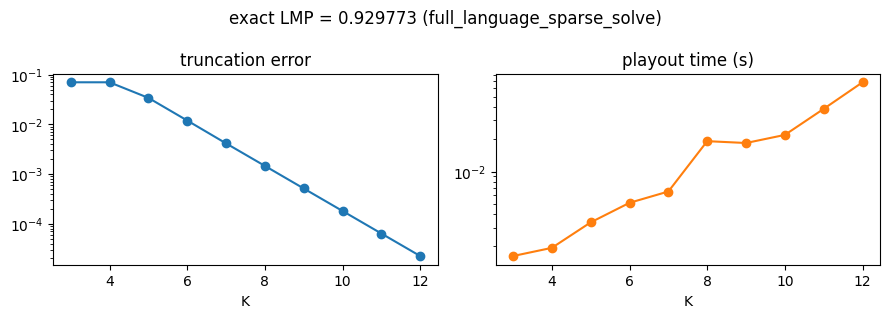

In [5]:
import time
exact = lmp.precision_language_mass(log, loop_model)
rows = []
for k in range(3, 13):
    start = time.perf_counter()
    bounded = lmp.precision_language_mass(log, loop_model, method="playout", max_trace_length=k)
    rows.append({"K": k, "bounded": bounded.value, "abs_error": bounded.value - exact.value,
                 "seconds": time.perf_counter() - start})
errors = pd.DataFrame(rows)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.2))
a1.semilogy(errors["K"], errors["abs_error"], marker="o"); a1.set_xlabel("K"); a1.set_title("truncation error")
a2.semilogy(errors["K"], errors["seconds"], marker="o", color="C1"); a2.set_xlabel("K"); a2.set_title("playout time (s)")
fig.suptitle(f"exact LMP = {exact.value:.6f} ({exact.certification})"); fig.tight_layout()

## When compilation does not finish

Concurrency multiplies reachable markings. The library never returns a silently truncated automaton: when the state or time limit is hit, the result is `incomplete` and carries the reason.

In [6]:
activities = [f"t{i}" for i in range(11)]
wide = pm4py.parse_process_tree("+(" + ", ".join(f"*('{a}', tau)" for a in activities) + ")")  # 11 concurrent loops
log = [tuple(activities)]
for limit in (1_000, 50_000):
    r = lmp.precision_language_mass(log, wide, state_limit=limit)
    print(f"state_limit={limit:>6}:", r, "| reachability states explored:", r.reachability_states)

state_limit=  1000: LMPResult(status=incomplete, reason='reachability_state_limit') | reachability states explored: 1000


state_limit= 50000: LMPResult(status=exact, value=5.82247e-13, certification='full_language_sparse_solve') | reachability states explored: 2050


Taken together the statuses separate three regimes: models for which LMP is **exact**, models for which only a **certified interval** is available, and models whose language could not be represented (**incomplete**).